# Pipeline de Análise de Modelos 

O presente Jupyter Notebook tem por objetivo realizar a análise de desempenho dos principais modelos vlm generativos video-texto-to-text. Serão avaliadas 4 tarefas:

1. Detecção de acidentes -> Capacidade do modelo identificar a ocorrência de acidentes.
2. Localização temporal -> Capacidade do modelo retornar o timestamp correspondente ao frame do primeiro impacto.
3. Localização espacial ->  Capacidade do modelo dividir o frame em um grid 3x3 e identificar em qual setor o impacto é visível.
4. Classificação -> Capacidade do modelo de inferir o tipo de impacto entre veículos dentro de 5 categorias.

![Esquema de Respostas Esperadas para Cada Tarefa](../docs/tarefas.jpg)
 

## Importação de Dependências, Modelo e Subconjunto de Dados

In [ ]:
import os
import gc
import re
import time
import math
import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch


from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
)

from transformers import AutoProcessor, LlavaOnevisionForConditionalGeneration

In [3]:
MODEL_ID = "llava-hf/llava-onevision-qwen2-0.5b-ov-hf"

CSV_PATH = Path(r"./accident_subset_100.csv")

NUM_FRAMES = 16
MAX_NEW_TOKENS_CLASSIFICATION = 16
MAX_NEW_TOKENS_TIME = 16

DO_SAMPLE = False

RESULTS_CSV = Path("./vlm_accident_results.csv")
METRICS_JSON = Path("./vlm_accident_metrics.json")

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [5]:
model = LlavaOnevisionForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    low_cpu_mem_usage=True,
).to(device)

processor = AutoProcessor.from_pretrained(MODEL_ID)

processor.patch_size = model.config.vision_config.patch_size

model.eval()

print("Modelo carregado:", MODEL_ID)

Loading weights:   0%|          | 0/716 [00:00<?, ?it/s]

Modelo carregado: llava-hf/llava-onevision-qwen2-0.5b-ov-hf


In [6]:
df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)
display(df.head())
print("\nColunas:")
print(df.columns.tolist())

Shape: (100, 28)


,sample_id,path,type,rollover,accident_time,accident_frame,center_x,center_y,x1,y1,...,duration,height,width,split_in_distribution,split_geo_aware,fps,time_frame_diff_s,grid_col,grid_row,video_file
0,acc_000,real_videos/xYbFnmG3-Og_00.mp4,t-bone,0,3.333000,49,0.708456,0.763898,0.617019,0.710300,...,29.958000,720,960,test,test,14.553709,0.033839,3,3,C:\Users\reisi\accident\ACCIDENT\real_videos\x...
1,acc_001,real_videos/uwdOQc-iC_c_00.mp4,sideswipe,0,5.667000,84,0.318698,0.440228,0.284251,0.414647,...,28.583000,720,960,test,test,14.729035,0.036021,1,2,C:\Users\reisi\accident\ACCIDENT\real_videos\u...
2,acc_002,real_videos/Pjuu3TEEonY_00.mp4,single,0,4.600000,137,0.195419,0.166544,0.166219,0.149455,...,10.533000,1080,1620,test,test,25.728662,0.724801,1,1,C:\Users\reisi\accident\ACCIDENT\real_videos\P...
3,acc_003,real_videos/8j-qfY6_Bxg_00.mp4,sideswipe,0,3.958333,59,0.183820,0.385592,0.096443,0.253362,...,13.291666,720,1056,test,test,14.971788,0.017588,1,2,C:\Users\reisi\accident\ACCIDENT\real_videos\8...
4,acc_004,real_videos/oWLWFTK4QdU_01.mp4,sideswipe,0,7.700000,193,0.826780,0.225896,0.814580,0.208451,...,10.200000,1080,1920,test,test,25.000000,0.020000,3,1,C:\Users\reisi\accident\ACCIDENT\real_videos\o...



Colunas:
['sample_id', 'path', 'type', 'rollover', 'accident_time', 'accident_frame', 'center_x', 'center_y', 'x1', 'y1', 'x2', 'y2', 'region', 'scene_layout', 'weather', 'day_time', 'quality', 'no_frames', 'duration', 'height', 'width', 'split_in_distribution', 'split_geo_aware', 'fps', 'time_frame_diff_s', 'grid_col', 'grid_row', 'video_file']


In [7]:
# -------------------------
# Normalização dos tipos
# -------------------------}

numeric_cols = [
    "accident_time",
    "accident_frame",
    "center_x",
    "center_y",
    "grid_col",
    "grid_row",
    "duration",
    "fps",
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["type"] = df["type"].astype(str).str.strip().str.lower()

# -------------------------
# Ground truth - ocorrência
# -------------------------
# Em ACCIDENT, a existência de `accident_time` é usada como indicador
# de ocorrência quando a coluna está disponível.
df["gt_occurrence"] = np.where(
    df["accident_time"].notna(),
    "Yes",
    "No",
)

# -------------------------
# Ground truth - tempo
# -------------------------
df["gt_time_s"] = df["accident_time"]

# -------------------------
# Ground truth - impacto
# -------------------------
VALID_IMPACTS = [
    "rear-end",
    "t-bone",
    "single",
    "head-on",
    "sideswipe",
]

df["gt_impact"] = df["type"].where(
    df["type"].isin(VALID_IMPACTS),
    np.nan,
)

# -------------------------
# Ground truth - espaço
# -------------------------

GRID_LABELS = {
    (1, 1): "top-left",
    (1, 2): "top-center",
    (1, 3): "top-right",
    (2, 1): "middle-left",
    (2, 2): "center",
    (2, 3): "middle-right",
    (3, 1): "bottom-left",
    (3, 2): "bottom-center",
    (3, 3): "bottom-right",
}

df["grid_col"] = pd.to_numeric(df["grid_col"], errors="coerce")
df["grid_row"] = pd.to_numeric(df["grid_row"], errors="coerce")

df["gt_spatial"] = [
    GRID_LABELS.get((row, col), np.nan)
    for row, col in zip(df["grid_row"], df["grid_col"])
]

# ID estável para relacionar as 4 inferências.
df["sample_id"] = df["sample_id"].astype(str)

# Reordenação útil para inspeção.
GT_COLUMNS = [
    "sample_id",
    "path",
    "video_file",
    "gt_occurrence",
    "gt_time_s",
    "gt_spatial",
    "gt_impact",
    "duration",
    "grid_row",
    "grid_col",
]

display(df[GT_COLUMNS].head(10))

,sample_id,path,video_file,gt_occurrence,gt_time_s,gt_spatial,gt_impact,duration,grid_row,grid_col
0,acc_000,real_videos/xYbFnmG3-Og_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\x...,Yes,3.333000,bottom-right,t-bone,29.958000,3,3
1,acc_001,real_videos/uwdOQc-iC_c_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\u...,Yes,5.667000,middle-left,sideswipe,28.583000,2,1
2,acc_002,real_videos/Pjuu3TEEonY_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\P...,Yes,4.600000,top-left,single,10.533000,1,1
3,acc_003,real_videos/8j-qfY6_Bxg_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\8...,Yes,3.958333,middle-left,sideswipe,13.291666,2,1
4,acc_004,real_videos/oWLWFTK4QdU_01.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\o...,Yes,7.700000,top-right,sideswipe,10.200000,1,3
5,acc_005,real_videos/5uh8-3q51uI_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\5...,Yes,5.866666,middle-left,rear-end,29.966666,2,1
6,acc_006,real_videos/1jCpA4y5NHY_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\1...,Yes,3.700000,bottom-right,rear-end,29.967000,3,3
7,acc_007,real_videos/0GPuugnrf3Y_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\0...,Yes,11.667000,top-center,t-bone,30.000000,1,2
8,acc_008,real_videos/FVZu22TdJwc_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\F...,Yes,2.542000,center,head-on,29.958000,2,2
9,acc_009,real_videos/SBTD7z4A1y8_00.mp4,C:\Users\reisi\accident\ACCIDENT\real_videos\S...,Yes,1.600000,bottom-right,head-on,30.000000,3,3


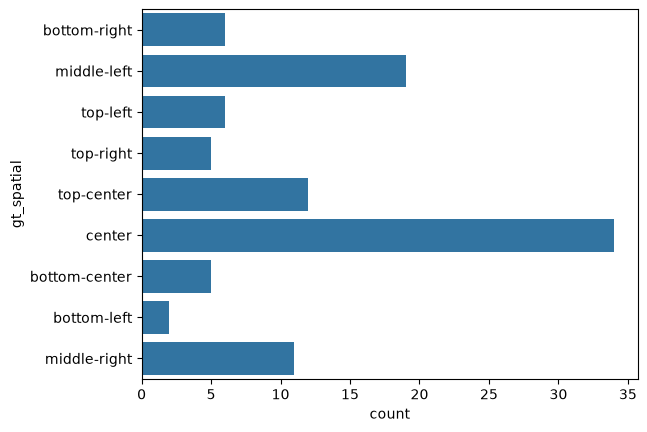

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, y="gt_spatial")  
plt.show()

In [9]:
def sample_frames(video_path, num_frames=16):
    video = cv2.VideoCapture(str(video_path))

    if not video.isOpened():
        raise RuntimeError(f"Não foi possível abrir o vídeo: {video_path}")

    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        video.release()
        raise RuntimeError(f"Vídeo sem frames válidos: {video_path}")

    indices = np.linspace(
        0,
        total_frames - 1,
        num=min(num_frames, total_frames),
        dtype=int,
    )

    frames = []

    for index in indices:
        video.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        ret, frame = video.read()

        if not ret:
            continue

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(Image.fromarray(frame))

    video.release()

    if not frames:
        raise RuntimeError(f"Nenhum frame foi extraído: {video_path}")

    return frames

Definição dos prompts para cada tarefa com foco em saída formatada.

In [10]:
PROMPTS = {
    "occurrence": (
        "Analyze the traffic video. "
        "Determine whether a traffic accident occurs in the video. "
        "Answer with exactly one word: Yes or No."
    ),

    "temporal": (
        "Analyze the traffic video and locate the traffic accident. "
        "Return the approximate time, in seconds from the beginning of the video, "
        "when the accident occurs. "
        "Answer with only one number in seconds, using a decimal point. "
        "Do not include units or explanation."
    ),

    "spatial": (
        "Analyze the traffic video and identify the main location of the accident. "
        "Divide the image into a 3x3 grid and choose exactly one label. "
        "Valid labels are: top-left, top-center, top-right, "
        "middle-left, center, middle-right, "
        "bottom-left, bottom-center, bottom-right. "
        "Answer with exactly one valid label and nothing else."
    ),

    "impact": (
        "Analyze the traffic video and classify the type of traffic accident. "
        "Choose exactly one class from: rear-end, t-bone, single, head-on, sideswipe. "
        "Answer with exactly one class and nothing else."
    ),
}

In [11]:
def build_inputs(prompt, frames):
    conversation = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {"type": "video"},
            ],
        }
    ]

    chat_prompt = processor.apply_chat_template(
        conversation,
        add_generation_prompt=True,
    )

    inputs = processor(
        text=chat_prompt,
        videos=frames,
        padding=True,
        return_tensors="pt",
    )

    return inputs.to(model.device)

In [12]:
@torch.inference_mode()
def generate_answer(prompt, frames, max_new_tokens=16):
    inputs = build_inputs(prompt, frames)

    input_length = inputs["input_ids"].shape[1]

    start = time.perf_counter()

    output_ids = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=DO_SAMPLE,
    )

    elapsed = time.perf_counter() - start

    generated_ids = output_ids[:, input_length:]

    answer = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
    )[0].strip()

    return {
        "raw_response": answer,
        "inference_time_s": elapsed,
        "generated_tokens": int(generated_ids.shape[1]),
    }

In [13]:
def parse_occurrence(text):
    if not isinstance(text, str):
        return np.nan

    match = re.search(r"\b(yes|no)\b", text.lower())

    return match.group(1).capitalize() if match else np.nan


def parse_time(text):
    if not isinstance(text, str):
        return np.nan

    # Aceita 3,33 e 3.33; evita números pertencentes a palavras.
    match = re.search(r"(?<![A-Za-z])\d+(?:[\.,]\d+)?", text)

    if not match:
        return np.nan

    value = match.group(0).replace(",", ".")

    try:
        return float(value)
    except ValueError:
        return np.nan


SPATIAL_LABELS = sorted(GRID_LABELS.values(), key=len, reverse=True)


def parse_spatial(text):
    if not isinstance(text, str):
        return np.nan

    normalized = text.lower().strip()

    for label in SPATIAL_LABELS:
        if re.search(rf"\b{re.escape(label)}\b", normalized):
            return label

    return np.nan


def parse_impact(text):
    if not isinstance(text, str):
        return np.nan

    normalized = text.lower()

    for label in VALID_IMPACTS:
        if re.search(rf"\b{re.escape(label)}\b", normalized):
            return label

    return np.nan

## Experimento com Llava-OneVision-Qwen2-0.5b-hf

In [15]:
# Teste rápido com o primeiro vídeo válido.

test_row = df.iloc[0]
test_video = test_row["video_file"]
num_frames = math.ceil(test_row["fps"])

frames = sample_frames(test_video, num_frames)

print("Vídeo:", test_video)
print("Frames:", len(frames))

for task, prompt in PROMPTS.items():
    max_tokens = (
        MAX_NEW_TOKENS_TIME
        if task == "temporal"
        else MAX_NEW_TOKENS_CLASSIFICATION
    )

    result = generate_answer(
        prompt,
        frames,
        max_new_tokens=max_tokens,
    )

    print(f"\n[{task}]")
    print("Resposta:", result["raw_response"])
    print("Tempo:", result["inference_time_s"])

Vídeo: C:\Users\reisi\accident\ACCIDENT\real_videos\xYbFnmG3-Og_00.mp4
Frames: 14

[occurrence]
Resposta: Yes
Tempo: 2.527633899997454

[temporal]
Resposta: 10
Tempo: 2.2960617000062484

[spatial]
Resposta: bottom-right
Tempo: 2.3249706999922637

[impact]
Resposta: head-on
Tempo: 2.259445300005609


In [15]:
df.iloc[0]

sample_id                                                          acc_000
path                                        real_videos/xYbFnmG3-Og_00.mp4
type                                                                t-bone
rollover                                                                 0
accident_time                                                        3.333
accident_frame                                                          49
center_x                                                          0.708456
center_y                                                          0.763898
x1                                                                0.617019
y1                                                                  0.7103
x2                                                                0.799894
y2                                                                0.817497
region                                                            New_York
scene_layout             

Para a primeira inferência:
  
    * Acertou a ocorrência (aqui só estamos avaliando se vai detectar, já que 100% das amostras são positivas);
    * Errou o tempo: chutou 10 segundos, o ground truth é de 3,333, tendo o vídeo 30s de duração;
    * Acertou a localização espacial: bottom-right;
    * Errou a classificação: chutou head-on para um caso de t-bone.

In [16]:
def run_evaluation(dataframe, save_every=10):
    results = []

    for idx, row in dataframe.reset_index(drop=True).iterrows():
        sample_id = row["sample_id"]
        video_path = row["video_file"]

        print(f"[{idx + 1}/{len(dataframe)}] {sample_id}")

        base = {
            "sample_id": sample_id,
            "video_file": video_path,
        }

        try:
            frames = sample_frames(
                video_path,
                num_frames=NUM_FRAMES,
            )
        except Exception as exc:
            print("  ERRO ao carregar vídeo:", exc)

            for task in PROMPTS:
                results.append({
                    **base,
                    "task": task,
                    "raw_response": np.nan,
                    "prediction": np.nan,
                    "inference_time_s": np.nan,
                    "generated_tokens": np.nan,
                    "error": str(exc),
                })

            continue

        for task, prompt in PROMPTS.items():
            try:
                max_tokens = (
                    MAX_NEW_TOKENS_TIME
                    if task == "temporal"
                    else MAX_NEW_TOKENS_CLASSIFICATION
                )

                result = generate_answer(
                    prompt,
                    frames,
                    max_new_tokens=max_tokens,
                )

                raw = result["raw_response"]

                if task == "occurrence":
                    prediction = parse_occurrence(raw)
                elif task == "temporal":
                    prediction = parse_time(raw)
                elif task == "spatial":
                    prediction = parse_spatial(raw)
                elif task == "impact":
                    prediction = parse_impact(raw)
                else:
                    prediction = np.nan

                results.append({
                    **base,
                    "task": task,
                    "raw_response": raw,
                    "prediction": prediction,
                    "inference_time_s": result["inference_time_s"],
                    "generated_tokens": result["generated_tokens"],
                    "error": np.nan,
                })

                print(f"  {task}: {raw}")

            except Exception as exc:
                print(f"  ERRO em {task}:", exc)

                results.append({
                    **base,
                    "task": task,
                    "raw_response": np.nan,
                    "prediction": np.nan,
                    "inference_time_s": np.nan,
                    "generated_tokens": np.nan,
                    "error": str(exc),
                })

        # Checkpoint periódico.
        if (idx + 1) % save_every == 0:
            checkpoint = pd.DataFrame(results)
            checkpoint.to_csv(
                RESULTS_CSV,
                index=False,
                encoding="utf-8-sig",
            )
            print(f"  Checkpoint salvo em {RESULTS_CSV}")

        # Liberação explícita de objetos temporários.
        del frames
        if device == "cuda":
            torch.cuda.empty_cache()

    results_df = pd.DataFrame(results)

    results_df.to_csv(
        RESULTS_CSV,
        index=False,
        encoding="utf-8-sig",
    )

    return results_df

In [17]:
results_df = run_evaluation(df)

print("\nShape dos resultados:", results_df.shape)
display(results_df.head(12))

[1/100] acc_000
  occurrence: Yes
  temporal: 10
  spatial: bottom-right
  impact: head-on
[2/100] acc_001
  occurrence: Yes
  temporal: 1:50
  spatial: top-right
  impact: The traffic video shows a single car that has veered off the road and into
[3/100] acc_002
  occurrence: Yes
  temporal: 10
  spatial: top-right
  impact: head-on
[4/100] acc_003
  occurrence: Yes
  temporal: 15
  spatial: top-right
  impact: single
[5/100] acc_004
  occurrence: No
  temporal: 0.33
  spatial: top-right
  impact: head-on
[6/100] acc_005
  occurrence: No
  temporal: 10
  spatial: top-right
  impact: The traffic video shows a single car that appears to have veered off the road
[7/100] acc_006
  occurrence: No
  temporal: 10
  spatial: top-right
  impact: The traffic video shows a single car that has veered off the road and collided
[8/100] acc_007
  occurrence: No
  temporal: 1:03
  spatial: top-right
  impact: head-on
[9/100] acc_008
  occurrence: Yes
  temporal: 10
  spatial: top-right
  impact: head

,sample_id,video_file,task,raw_response,prediction,inference_time_s,generated_tokens,error
0,acc_000,C:\Users\reisi\accident\ACCIDENT\real_videos\x...,occurrence,Yes,Yes,11.623706,2,NaN
1,acc_000,C:\Users\reisi\accident\ACCIDENT\real_videos\x...,temporal,10,10.0,20.570910,3,NaN
2,acc_000,C:\Users\reisi\accident\ACCIDENT\real_videos\x...,spatial,bottom-right,bottom-right,25.106755,3,NaN
3,acc_000,C:\Users\reisi\accident\ACCIDENT\real_videos\x...,impact,head-on,head-on,19.438093,3,NaN
4,acc_001,C:\Users\reisi\accident\ACCIDENT\real_videos\u...,occurrence,Yes,Yes,2.579323,2,NaN
5,acc_001,C:\Users\reisi\accident\ACCIDENT\real_videos\u...,temporal,1:50,1.0,2.648905,5,NaN
6,acc_001,C:\Users\reisi\accident\ACCIDENT\real_videos\u...,spatial,top-right,top-right,4.062178,3,NaN
7,acc_001,C:\Users\reisi\accident\ACCIDENT\real_videos\u...,impact,The traffic video shows a single car that has ...,single,3.009063,16,NaN
8,acc_002,C:\Users\reisi\accident\ACCIDENT\real_videos\P...,occurrence,Yes,Yes,2.583350,2,NaN
9,acc_002,C:\Users\reisi\accident\ACCIDENT\real_videos\P...,temporal,10,10.0,2.611394,3,NaN


In [22]:
def classification_metrics(y_true, y_pred, labels):
    valid = pd.notna(y_true) & pd.notna(y_pred)

    y_true = pd.Series(y_true)[valid].astype(str)
    y_pred = pd.Series(y_pred)[valid].astype(str)

    if len(y_true) == 0:
        return {
            "n_valid": 0,
            "accuracy": np.nan,
            "precision_macro": np.nan,
            "recall_macro": np.nan,
            "f1_macro": np.nan,
            "f1_weighted": np.nan,
            "classification_report": {},
            "confusion_matrix": [],
        }

    return {
        "n_valid": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(
            precision_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        ),
        "recall_macro": float(
            recall_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_macro": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="macro",
                zero_division=0,
            )
        ),
        "f1_weighted": float(
            f1_score(
                y_true,
                y_pred,
                labels=labels,
                average="weighted",
                zero_division=0,
            )
        ),
        "classification_report": classification_report(
            y_true,
            y_pred,
            labels=labels,
            output_dict=True,
            zero_division=0,
        ),
    }


metrics = {}

occ = results_df[results_df["task"] == "occurrence"].merge(
    df[["sample_id", "gt_occurrence"]],
    on="sample_id",
    how="left"
)

metrics["occurrence"] = classification_metrics(
    occ["gt_occurrence"],
    occ["prediction"],
    labels=["Yes", "No"],
)

# 3. Espaço
spatial = results_df[results_df["task"] == "spatial"].merge(
    df[["sample_id", "gt_spatial"]],
    on="sample_id",
    how="left"
)

metrics["spatial"] = classification_metrics(
    spatial["gt_spatial"],
    spatial["prediction"],
    labels=list(GRID_LABELS.values()),
)

# 4. Impacto
impact = results_df[results_df["task"] == "impact"].merge(
    df[["sample_id", "gt_impact"]],
    on="sample_id",
    how="left"
)

metrics["impact"] = classification_metrics(
    impact["gt_impact"],
    impact["prediction"],
    labels=VALID_IMPACTS,
)

for task in ["occurrence", "spatial", "impact"]:
    print(f"\n=== {task.upper()} ===")
    print("Accuracy:", metrics[task]["accuracy"])
    print("F1 macro:", metrics[task]["f1_macro"])
    print("F1 weighted:", metrics[task]["f1_weighted"])


=== OCCURRENCE ===
Accuracy: 0.52
F1 macro: 0.34210526315789475
F1 weighted: 0.6842105263157895

=== SPATIAL ===
Accuracy: 0.06
F1 macro: 0.03558460421205519
F1 weighted: 0.018235294117647058

=== IMPACT ===
Accuracy: 0.15
F1 macro: 0.11064935064935066
F1 weighted: 0.11064935064935065


Obs: Nesse caso, a acurácia seria um recall, dados que não há casos negativos para a tarefa de detecção de ocorrência (occurrence)

In [23]:
def temporal_metrics(y_true, y_pred, tolerances=(0.5, 1.0, 2.0)):
    data = pd.DataFrame({
        "true": pd.to_numeric(y_true, errors="coerce"),
        "pred": pd.to_numeric(y_pred, errors="coerce"),
    }).dropna()

    if data.empty:
        return {
            "n_valid": 0,
            "mae_s": np.nan,
            "rmse_s": np.nan,
            "mean_error_s": np.nan,
            "median_absolute_error_s": np.nan,
        }

    error = data["pred"] - data["true"]
    abs_error = error.abs()

    result = {
        "n_valid": int(len(data)),
        "mae_s": float(mean_absolute_error(data["true"], data["pred"])),
        "rmse_s": float(np.sqrt(mean_squared_error(data["true"], data["pred"]))),
        "mean_error_s": float(error.mean()),
        "median_absolute_error_s": float(abs_error.median()),
    }

    for tolerance in tolerances:
        result[f"accuracy_within_{str(tolerance).replace('.', '_')}_s"] = float(
            (abs_error <= tolerance).mean()
        )

    return result


temporal = results_df[results_df["task"] == "temporal"].merge(
    df[["sample_id", "gt_time_s"]],
    on="sample_id",
    how="left"
)

metrics["temporal"] = temporal_metrics(
    temporal["gt_time_s"],
    temporal["prediction"],
)

metrics["temporal"]

{'n_valid': 100,
 'mae_s': 6.972565019999999,
 'rmse_s': 16.84981203266593,
 'mean_error_s': 3.9083597,
 'median_absolute_error_s': 6.021,
 'accuracy_within_0_5_s': 0.06,
 'accuracy_within_1_0_s': 0.07,
 'accuracy_within_2_0_s': 0.11}

In [24]:
summary = pd.DataFrame([
    {
        "task": "occurrence",
        "n_valid": metrics["occurrence"]["n_valid"],
        "accuracy": metrics["occurrence"]["accuracy"],
        "f1_macro": metrics["occurrence"]["f1_macro"],
        "f1_weighted": metrics["occurrence"]["f1_weighted"],
    },
    {
        "task": "spatial",
        "n_valid": metrics["spatial"]["n_valid"],
        "accuracy": metrics["spatial"]["accuracy"],
        "f1_macro": metrics["spatial"]["f1_macro"],
        "f1_weighted": metrics["spatial"]["f1_weighted"],
    },
    {
        "task": "impact",
        "n_valid": metrics["impact"]["n_valid"],
        "accuracy": metrics["impact"]["accuracy"],
        "f1_macro": metrics["impact"]["f1_macro"],
        "f1_weighted": metrics["impact"]["f1_weighted"],
    },
    {
        "task": "temporal",
        "n_valid": metrics["temporal"]["n_valid"],
        "accuracy": metrics["temporal"].get("accuracy_within_1_0_s", np.nan),
        "f1_macro": np.nan,
        "f1_weighted": np.nan,
        "mae_s": metrics["temporal"]["mae_s"],
        "rmse_s": metrics["temporal"]["rmse_s"],
        "accuracy_±1s": metrics["temporal"].get(
            "accuracy_within_1_0_s", np.nan
        ),
    },
])

display(summary)

,task,n_valid,accuracy,f1_macro,f1_weighted,mae_s,rmse_s,accuracy_±1s
0,occurrence,100,0.52,0.342105,0.684211,NaN,NaN,NaN
1,spatial,100,0.06,0.035585,0.018235,NaN,NaN,NaN
2,impact,100,0.15,0.110649,0.110649,NaN,NaN,NaN
3,temporal,100,0.07,NaN,NaN,6.972565,16.849812,0.07


In [25]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

Matriz de confusão — localização espacial


<Figure size 1200x600 with 0 Axes>

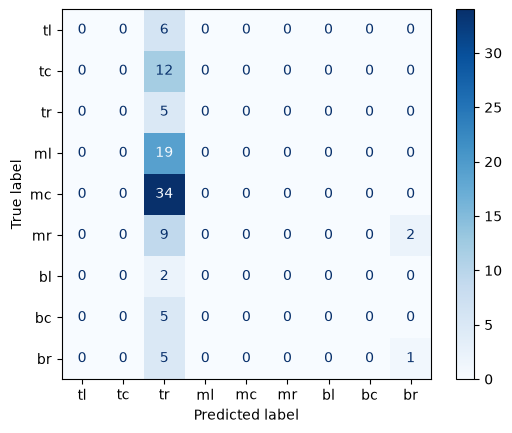


Matriz de confusão — tipo de impacto


<Figure size 1200x600 with 0 Axes>

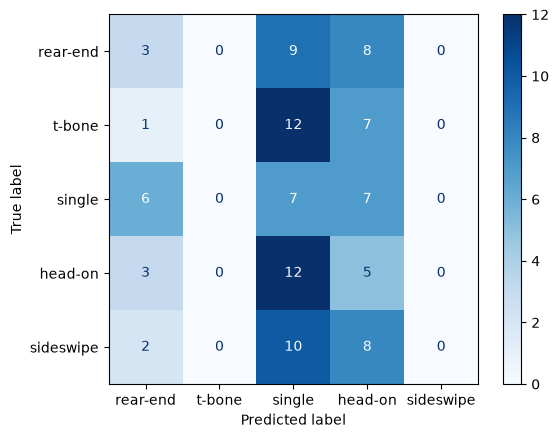

,pred:rear-end,pred:t-bone,pred:single,pred:head-on,pred:sideswipe
true:rear-end,3,0,9,8,0
true:t-bone,1,0,12,7,0
true:single,6,0,7,7,0
true:head-on,3,0,12,5,0
true:sideswipe,2,0,10,8,0


In [26]:
def show_confusion(task, labels, display_labels=None):

    if not display_labels:
        display_labels = labels
    
    subset = results_df[results_df["task"] == task].merge(
            df[["sample_id", f"gt_{task}"]],
        on="sample_id",
        how="left"
    )

    valid = (
        subset["prediction"].notna()
        & subset["gt_" + ("spatial" if task == "spatial" else "impact")].notna()
    )

    if task == "spatial":
        y_true = subset.loc[valid, "gt_spatial"]
        y_pred = subset.loc[valid, "prediction"]
    else:
        y_true = subset.loc[valid, "gt_impact"]
        y_pred = subset.loc[valid, "prediction"]

    plt.figure(figsize=(12, 6))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
    cmd.plot(cmap='Blues')
    plt.show()

    return pd.DataFrame(
        cm,
        index=[f"true:{x}" for x in labels],
        columns=[f"pred:{x}" for x in labels],
    )

GRID_LABELS = {
    (1, 1): "top-left",
    (1, 2): "top-center",
    (1, 3): "top-right",
    (2, 1): "middle-left",
    (2, 2): "center",
    (2, 3): "middle-right",
    (3, 1): "bottom-left",
    (3, 2): "bottom-center",
    (3, 3): "bottom-right",
}

impact_map = {
    "top_left": "tl",
    "top_center": "tc",
    "top_right": "tr",
    "middle_left": "ml",
    "center": "mc",
    "middle_right": "mr",
    "bottom_left": "bl",
    "bottom_center": "bc",
    "bottom_right": "br",
}


print("Matriz de confusão — localização espacial")
show_confusion("spatial", list(GRID_LABELS.values()), impact_map.values())

print("\nMatriz de confusão — tipo de impacto")
show_confusion("impact", VALID_IMPACTS)


In [27]:
invalid_summary = (
    results_df
    .assign(valid_prediction=results_df["prediction"].notna())
    .groupby("task")
    .agg(
        total=("sample_id", "size"),
        valid=("valid_prediction", "sum"),
    )
)

invalid_summary["invalid"] = (
    invalid_summary["total"] - invalid_summary["valid"]
)

invalid_summary["invalid_rate"] = (
    invalid_summary["invalid"] / invalid_summary["total"]
)

display(invalid_summary)


,total,valid,invalid,invalid_rate
task,,,,
impact,100,100,0,0.0
occurrence,100,100,0,0.0
spatial,100,100,0,0.0
temporal,100,100,0,0.0


In [28]:
# Maiores erros temporais
temporal_errors = temporal.copy()

temporal_errors["absolute_error_s"] = (
    temporal_errors["prediction"] - temporal_errors["gt_time_s"]
).abs()

display(
    temporal_errors[
        [
            "sample_id",
            "gt_time_s",
            "prediction",
            "absolute_error_s",
            "raw_response",
            "inference_time_s",
        ]
    ]
    .sort_values("absolute_error_s", ascending=False)
    .head(20)
)


,sample_id,gt_time_s,prediction,absolute_error_s,raw_response,inference_time_s
99,acc_099,5.750000,163.0,157.25,163,2.887804
3,acc_003,3.958333,15.0,11.041667,15,2.857839
87,acc_087,11.416666,0.5,10.916666,0.5,2.651777
7,acc_007,11.667000,1.0,10.667,1:03,2.379190
30,acc_030,4.791666,15.0,10.208334,15,2.614867
71,acc_071,10.333333,0.5,9.833333,0.5,2.906295
46,acc_046,0.600000,10.0,9.4,10,2.872669
31,acc_031,0.625000,10.0,9.375,The approximate time when the accident occurs ...,3.240600
73,acc_073,0.633000,10.0,9.367,10,2.851730
21,acc_021,0.800000,10.0,9.2,10,2.855826


In [33]:
# Converter tipos NumPy para tipos serializáveis.
def make_json_serializable(obj):
    if isinstance(obj, dict):
        return {str(k): make_json_serializable(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [make_json_serializable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj


with open(METRICS_JSON, "w", encoding="utf-8") as f:
    json.dump(
        make_json_serializable(metrics),
        f,
        ensure_ascii=False,
        indent=2,
    )

print("Resultados:", RESULTS_CSV.resolve())
print("Métricas:", METRICS_JSON.resolve())


Resultados: C:\Users\reisi\accident\codes\vlm_accident_results.csv
Métricas: C:\Users\reisi\accident\codes\vlm_accident_metrics.json


In [29]:
results_df = pd.read_csv("vlm_accident_results.csv")

In [30]:
results_df[results_df['task'] == "occurrence"]['raw_response'].value_counts()

raw_response
Yes    52
No     48
Name: count, dtype: int64

In [31]:
results_df[results_df['task'] == "spatial"]['raw_response'].value_counts()

raw_response
top-right       97
bottom-right     3
Name: count, dtype: int64

In [51]:
results_df[results_df['task'] == "temporal"]['raw_response'].value_counts()

raw_response
10                                                                   60
0.5                                                                   6
0                                                                     6
The approximate time when the accident occurs is 10 seconds.          4
The approximate time when the accident occurs is 1:50.                3
1:50                                                                  2
15                                                                    2
0.33                                                                  1
1:03                                                                  1
1:55                                                                  1
The traffic accident occurs at approximately 1:30.                    1
4.0                                                                   1
0.0                                                                   1
1.0                                                

In [32]:
results_df[results_df['task'] == "impact"]['raw_response'].value_counts()

raw_response
head-on                                                                                      35
single                                                                                       23
The traffic video shows a single car accident.                                                6
The traffic video shows a single car that appears to have veered off the road                 4
The traffic video shows a rear-end collision between two vehicles.                            4
The traffic video shows a single car that has veered off the road and into                    3
The traffic video shows a rear-end collision between two cars.                                3
The traffic video shows a single car that has been involved in a rear-end collision           3
The traffic video shows a single car involved in a rear-end collision.                        3
The traffic accident is a single car accident.                                                3
The traffic video shows a s

In [33]:
del results_df

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()